<a href="https://colab.research.google.com/github/midhunpmathew/L-Net/blob/main/plant_leaves_Bell_Pepper_MultiTask_TypeAware_modified_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bell Pepper — Multi-Task Leaf + Crop Classification (Type-Aware)

This notebook trains a **dual-head model** that predicts:
- **leaf condition**  -> `healthy` / `unhealthy` / `none`
- **crop condition**  -> `healthy` / `rotten`  / `none`

from a single image, and reports the right thing for **any** photo:

| You upload...           | Leaf head says | Crop head says | Reported            |
|-------------------------|----------------|----------------|---------------------|
| a leaf-only photo       | healthy/unhealthy | none        | **Leaf: ...**       |
| a crop/fruit-only photo | none           | healthy/rotten | **Crop: ...**       |
| a photo with both       | healthy/unhealthy | healthy/rotten | **Leaf + Crop**  |

The trick (vs. the old version): the model is trained on **single-object images too**,
not only side-by-side composites. When a leaf photo is shown, its crop label is `none`
(and vice-versa). This teaches each head to output `none` when its object is absent, so
the model itself decides leaf-only / crop-only / both — the separate content-type
detector (kept later in the notebook) is now just a cross-check, not the sole decision.


## Step 1: Mount Drive and extract dataset (unchanged from original)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Bell Pepper.zip"
extract_path = "/content/Dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [ ]:
import os
from PIL import Image

dataset_path = "/content/Dataset/Bell pepper"
target_size = (256, 256)

for class_name in os.listdir(dataset_path):
    class_folder = os.path.join(dataset_path, class_name)
    if os.path.isdir(class_folder):
        for filename in os.listdir(class_folder):
            file_path = os.path.join(class_folder, filename)
            try:
                img = Image.open(file_path)
                img = img.convert("RGB")
                img = img.resize(target_size, Image.LANCZOS)
                img.save(file_path)
            except Exception as e:
                print(f"Error processing {file_path}: {e}")

print("All images resized to 256x256 successfully!")

All images resized to 256x256 successfully!


## Step 2: Build a balanced mixed dataset (single-object + composite)

Three kinds of training samples, all carrying BOTH labels:

1. **Leaf-only** image  ->  `leaf_label = healthy/unhealthy`, `crop_label = none`
2. **Crop-only** image  ->  `leaf_label = none`, `crop_label = healthy/rotten`
3. **Composite** image (leaf pasted beside crop)  ->  both real labels

### Why the three group sizes must be equal

The leaf head sees `none` **only** from crop-only rows, but sees `healthy`/`unhealthy`
from composites *and* leaf-only rows. Writing `C`, `L`, `R` for the number of composite /
leaf-only / crop-only images, and splitting each group exactly 50-50:

```
leaf healthy = C/2 + L/2      leaf none = R
crop healthy = C/2 + R/2      crop none = L
```

Setting `leaf healthy == leaf none` and `crop healthy == crop none` gives **L = R = C**.
So all three groups get the same size `PER_CLASS`, every class lands on exactly
`PER_CLASS` images, and the dataset totals `3 x PER_CLASS`.

Splits are made **deterministically** (exact counts, then shuffled) rather than with
`random.choice`, which only approximates 50-50 and produced the earlier 6092/5908 skew.


In [ ]:
import random
import pandas as pd
from PIL import Image

base_path = "/content/Dataset/Bell pepper"

leaf_dirs = {
    "healthy": os.path.join(base_path, "Leaf Healthy"),
    "unhealthy": os.path.join(base_path, "Leaf Unhealthy"),
}
crop_dirs = {
    "healthy": os.path.join(base_path, "Crop Healthy"),
    "rotten": os.path.join(base_path, "Crop Rotten"),
}

leaf_files = {k: [os.path.join(v, f) for f in os.listdir(v)] for k, v in leaf_dirs.items()}
crop_files = {k: [os.path.join(v, f) for f in os.listdir(v)] for k, v in crop_dirs.items()}

for k, v in leaf_files.items():
    print(f"Leaf {k}: {len(v)} images")
for k, v in crop_files.items():
    print(f"Crop {k}: {len(v)} images")

Leaf healthy: 2954 images
Leaf unhealthy: 3449 images
Crop healthy: 611 images
Crop rotten: 591 images


In [ ]:
import random
import os
import pandas as pd
from PIL import Image

composite_dir = "/content/composite_dataset"
os.makedirs(composite_dir, exist_ok=True)

# ---------------------------------------------------------------------------
# PER_CLASS drives everything. Because L = R = C (see markdown above), setting all
# three groups to PER_CLASS makes every leaf class AND every crop class land on
# exactly PER_CLASS images.  Total dataset = 3 * PER_CLASS.
# Must be divisible by 4 so the composite leaf x crop combos split evenly.
# ---------------------------------------------------------------------------
PER_CLASS = 5000                     # -> 15000 rows, 5000 per class
assert PER_CLASS % 4 == 0, "PER_CLASS must be divisible by 4"

N_COMPOSITES = PER_CLASS
N_LEAF_ONLY  = PER_CLASS
N_CROP_ONLY  = PER_CLASS
IMG_SIZE = (256, 256)
NONE = "none"                        # sentinel: this object is absent

rng = random.Random(42)
leaf_keys = sorted(leaf_files.keys())    # ['healthy', 'unhealthy']
crop_keys = sorted(crop_files.keys())    # ['healthy', 'rotten']


def sample_paths(paths, n, rng):
    """Draw exactly n paths, cycling through reshuffled copies of the folder so every
    source file is reused as evenly as possible (instead of random-with-replacement,
    which over-picks some files and never picks others)."""
    out = []
    while len(out) < n:
        pool = list(paths)
        rng.shuffle(pool)
        out.extend(pool[: n - len(out)])
    return out


# --- how many paths each status needs in total -----------------------------
# leaf status k is used in: composites (PER_CLASS/2) + leaf-only rows (PER_CLASS/2)
leaf_pool = {k: sample_paths(leaf_files[k], PER_CLASS, rng) for k in leaf_keys}
crop_pool = {k: sample_paths(crop_files[k], PER_CLASS, rng) for k in crop_keys}
leaf_ptr = {k: 0 for k in leaf_keys}
crop_ptr = {k: 0 for k in crop_keys}

def take_leaf(k):
    p = leaf_pool[k][leaf_ptr[k]]; leaf_ptr[k] += 1; return p

def take_crop(k):
    p = crop_pool[k][crop_ptr[k]]; crop_ptr[k] += 1; return p


records = []

# ---- 1) composites: each (leaf_status, crop_status) combo exactly N/4 times ----
n_combo = N_COMPOSITES // 4
comp_pairs = []
for ls in leaf_keys:
    for cs in crop_keys:
        comp_pairs.extend([(ls, cs)] * n_combo)
rng.shuffle(comp_pairs)
# -> leaf healthy = leaf unhealthy = N/2 ; crop healthy = crop rotten = N/2

for i, (leaf_status, crop_status) in enumerate(comp_pairs):
    leaf_img = Image.open(take_leaf(leaf_status)).convert("RGB").resize((256, 256))
    crop_img = Image.open(take_crop(crop_status)).convert("RGB").resize((256, 256))

    canvas = Image.new("RGB", (512, 256))
    if rng.random() < 0.5:
        canvas.paste(leaf_img, (0, 0)); canvas.paste(crop_img, (256, 0))
    else:
        canvas.paste(crop_img, (0, 0)); canvas.paste(leaf_img, (256, 0))

    canvas = canvas.resize(IMG_SIZE, Image.LANCZOS)
    fname = os.path.join(composite_dir, f"both_{i}.jpg")
    canvas.save(fname, quality=95)
    records.append((fname, leaf_status, crop_status))

# ---- 2) leaf-only: exactly half per leaf status, crop_label = none ----------
leaf_only_status = []
for k in leaf_keys:
    leaf_only_status.extend([k] * (N_LEAF_ONLY // len(leaf_keys)))
rng.shuffle(leaf_only_status)
for k in leaf_only_status:
    records.append((take_leaf(k), k, NONE))

# ---- 3) crop-only: exactly half per crop status, leaf_label = none ----------
crop_only_status = []
for k in crop_keys:
    crop_only_status.extend([k] * (N_CROP_ONLY // len(crop_keys)))
rng.shuffle(crop_only_status)
for k in crop_only_status:
    records.append((take_crop(k), NONE, k))

df = pd.DataFrame(records, columns=["filepath", "leaf_label", "crop_label"])
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.to_csv("/content/composite_labels.csv", index=False)

# ---- verification ----------------------------------------------------------
print(f"Total training rows: {len(df)}\n")
print("Leaf label counts:"); print(df["leaf_label"].value_counts().sort_index())
print("\nCrop label counts:"); print(df["crop_label"].value_counts().sort_index())

assert df["leaf_label"].value_counts().nunique() == 1, "leaf classes not balanced!"
assert df["crop_label"].value_counts().nunique() == 1, "crop classes not balanced!"
print(f"\n[OK] every leaf class and every crop class has exactly {PER_CLASS} images.")

# how often each source photo had to be reused (>1 means duplicates exist)
for k in leaf_keys:
    print(f"  leaf '{k}': {PER_CLASS} draws from {len(leaf_files[k])} unique files "
          f"(~{PER_CLASS/len(leaf_files[k]):.1f}x reuse)")
for k in crop_keys:
    print(f"  crop '{k}': {PER_CLASS} draws from {len(crop_files[k])} unique files "
          f"(~{PER_CLASS/len(crop_files[k]):.1f}x reuse)")


Total training rows: 15000

Leaf label counts:
leaf_label
healthy      5000
none         5000
unhealthy    5000
Name: count, dtype: int64

Crop label counts:
crop_label
healthy    5000
none       5000
rotten     5000
Name: count, dtype: int64

[OK] every leaf class and every crop class has exactly 5000 images.
  leaf 'healthy': 5000 draws from 2954 unique files (~1.7x reuse)
  leaf 'unhealthy': 5000 draws from 3449 unique files (~1.4x reuse)
  crop 'healthy': 5000 draws from 611 unique files (~8.2x reuse)
  crop 'rotten': 5000 draws from 591 unique files (~8.5x reuse)


## Step 3: Label encoding and K-Fold split

`leaf_label` and `crop_label` are encoded as separate one-hot vectors. K-Fold is done on
the composite dataframe (same pattern as the original notebook), but each fold now needs
a `tf.data.Dataset` that yields two label outputs instead of `flow_from_dataframe`
(which only supports one `y_col`).

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import KFold

# Build class lists explicitly so "none" is always present and index order is stable,
# even if a fold happens not to contain every label.
leaf_classes = sorted(set(df["leaf_label"]) | {"none"})
crop_classes = sorted(set(df["crop_label"]) | {"none"})

leaf_to_idx = {c: i for i, c in enumerate(leaf_classes)}
crop_to_idx = {c: i for i, c in enumerate(crop_classes)}

print("Leaf classes:", leaf_classes)   # e.g. ['healthy', 'none', 'unhealthy']
print("Crop classes:", crop_classes)   # e.g. ['healthy', 'none', 'rotten']

IMG_SIZE = (256, 256)
IMG_SHAPE = (256, 256, 3)
BATCH_SIZE = 32

kf = KFold(n_splits=5, shuffle=True, random_state=42)


Leaf classes: ['healthy', 'none', 'unhealthy']
Crop classes: ['healthy', 'none', 'rotten']


In [ ]:
def load_and_preprocess(filepath, leaf_idx, crop_idx):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0

    leaf_onehot = tf.one_hot(leaf_idx, depth=len(leaf_classes))
    crop_onehot = tf.one_hot(crop_idx, depth=len(crop_classes))

    return img, {"leaf_output": leaf_onehot, "crop_output": crop_onehot}


def make_dataset(sub_df, training=True):
    filepaths = sub_df["filepath"].values
    leaf_idx = sub_df["leaf_label"].map(leaf_to_idx).values
    crop_idx = sub_df["crop_label"].map(crop_to_idx).values

    ds = tf.data.Dataset.from_tensor_slices((filepaths, leaf_idx, crop_idx))
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.shuffle(1024, seed=42)

    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

## Step 4: Dual-head Switch Transformer model

Same `PatchEmbedding`, `Expert`, `SwitchFFN`, `SwitchTransformerBlock` building blocks as
the original notebook — only `build_switch_transformer` changes, splitting into two
output heads instead of one.

In [ ]:
from tensorflow.keras import layers, Model


class PatchEmbedding(layers.Layer):
    def __init__(self, image_size=256, patch_size=16, embed_dim=128):
        super().__init__()
        self.num_patches = (image_size // patch_size) ** 2
        self.projection = layers.Conv2D(
            embed_dim, kernel_size=patch_size, strides=patch_size, padding="valid"
        )
        self.position_embedding = layers.Embedding(
            input_dim=self.num_patches, output_dim=embed_dim
        )

    def call(self, x):
        x = self.projection(x)
        x = tf.reshape(x, [tf.shape(x)[0], -1, x.shape[-1]])
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        x = x + self.position_embedding(positions)
        return x


class Expert(layers.Layer):
    def __init__(self, embed_dim, ff_dim):
        super().__init__()
        self.net = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="gelu"),
            layers.Dense(embed_dim)
        ])

    def call(self, x):
        return self.net(x)


class SwitchFFN(layers.Layer):
    def __init__(self, embed_dim, ff_dim, num_experts=4):
        super().__init__()
        self.num_experts = num_experts
        self.experts = [Expert(embed_dim, ff_dim) for _ in range(num_experts)]
        self.router = layers.Dense(num_experts)

    def call(self, x):
        router_logits = self.router(x)
        router_probs = tf.nn.softmax(router_logits, axis=-1)
        expert_index = tf.argmax(router_probs, axis=-1)

        expert_outputs = []
        for i, expert in enumerate(self.experts):
            expert_output = expert(x)
            mask = tf.cast(tf.equal(expert_index, i), tf.float32)
            mask = tf.expand_dims(mask, axis=-1)
            expert_outputs.append(expert_output * mask)

        return tf.add_n(expert_outputs)


class SwitchTransformerBlock(layers.Layer):
    def __init__(self, embed_dim=128, num_heads=4, ff_dim=256, num_experts=4, dropout=0.1):
        super().__init__()
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads
        )
        self.dropout1 = layers.Dropout(dropout)

        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.switch_ffn = SwitchFFN(embed_dim, ff_dim, num_experts)
        self.dropout2 = layers.Dropout(dropout)

    def call(self, x, training=False):
        attn_input = self.norm1(x)
        attn_output = self.attention(attn_input, attn_input)
        attn_output = self.dropout1(attn_output, training=training)
        x = x + attn_output

        ffn_input = self.norm2(x)
        ffn_output = self.switch_ffn(ffn_input)
        ffn_output = self.dropout2(ffn_output, training=training)
        x = x + ffn_output
        return x

In [ ]:
def build_multitask_switch_transformer(
    image_size=256,
    patch_size=16,
    num_leaf_classes=2,
    num_crop_classes=2,
    embed_dim=128,
    num_heads=4,
    ff_dim=256,
    num_experts=4,
    num_layers=4,
    dropout=0.1
):
    inputs = layers.Input(shape=(image_size, image_size, 3))

    x = PatchEmbedding(image_size, patch_size, embed_dim)(inputs)

    for _ in range(num_layers):
        x = SwitchTransformerBlock(
            embed_dim=embed_dim,
            num_heads=num_heads,
            ff_dim=ff_dim,
            num_experts=num_experts,
            dropout=dropout
        )(x)

    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x = layers.GlobalAveragePooling1D()(x)

    shared = layers.Dense(256, activation="gelu")(x)
    shared = layers.Dropout(dropout)(shared)

    leaf_branch = layers.Dense(64, activation="gelu")(shared)
    leaf_output = layers.Dense(num_leaf_classes, activation="softmax", name="leaf_output")(leaf_branch)

    crop_branch = layers.Dense(64, activation="gelu")(shared)
    crop_output = layers.Dense(num_crop_classes, activation="softmax", name="crop_output")(crop_branch)

    model = Model(inputs, [leaf_output, crop_output], name="MultiTask_Switch_Transformer")
    return model


def get_new_multitask_model():
    model = build_multitask_switch_transformer(
        image_size=256,
        patch_size=16,
        num_leaf_classes=len(leaf_classes),
        num_crop_classes=len(crop_classes),
    )
    model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-4, weight_decay=1e-4),
        loss={
            "leaf_output": "categorical_crossentropy",
            "crop_output": "categorical_crossentropy",
        },
        loss_weights={"leaf_output": 0.5, "crop_output": 0.5},
        metrics={
            "leaf_output": "accuracy",
            "crop_output": "accuracy",
        },
    )
    return model


get_new_multitask_model().summary()

Model: "MultiTask_Switch_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding     │ (None, 256, 128)  │    131,200 │ input_layer[0][0] │
│ (PatchEmbedding)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ switch_transformer… │ (None, 256, 128)  │    330,756 │ patch_embedding[… │
│ (SwitchTransformer… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ switch_transformer… │ (None, 256, 128)  │    330,756 │ switch_transform… │
│ (SwitchTransformer… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ switch_transformer… │ (None, 256, 128)  │    330,756 │ switch_transform… │
│ (SwitchTransformer… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ switch_transformer… │ (None, 256, 128)  │    330,756 │ switch_transform… │
│ (SwitchTransformer… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 256, 128)  │        256 │ switch_transform… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_36 (Dense)    │ (None, 256)       │     33,024 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 256)       │          0 │ dense_36[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_37 (Dense)    │ (None, 64)        │     16,448 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_38 (Dense)    │ (None, 64)        │     16,448 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaf_output (Dense) │ (None, 3)         │        195 │ dense_37[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ crop_output (Dense) │ (None, 3)         │        195 │ dense_38[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,520,790 (5.80 MB)

 Trainable params: 1,520,790 (5.80 MB)

 Non-trainable params: 0 (0.00 B)

## Step 5: K-Fold training

In [ ]:
import os

os.makedirs("/content/multitask_kfold", exist_ok=True)

fold_histories = []

for fold, (train_idx, val_idx) in enumerate(kf.split(df)):
    print(f"\nStarting Fold {fold+1}/5...")

    train_df = df.iloc[train_idx]
    val_df = df.iloc[val_idx]

    train_ds = make_dataset(train_df, training=True)
    val_ds = make_dataset(val_df, training=False)

    model = get_new_multitask_model()

    history = model.fit(train_ds, validation_data=val_ds, epochs=65)
    fold_histories.append(history.history)

    model.save(f"/content/multitask_kfold/multitask_fold_{fold+1}.h5")

print("All folds completed.")
for i, h in enumerate(fold_histories):
    print(f"Fold {i+1} - leaf_val_acc: {h['val_leaf_output_accuracy'][-1]:.4f}, "
          f"crop_val_acc: {h['val_crop_output_accuracy'][-1]:.4f}")


Starting Fold 1/5...
Epoch 1/65


/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py:870: UserWarning: Gradients do not exist for variables ['switch_transformer_block_4/switch_ffn_4/dense_47/kernel', 'switch_transformer_block_4/switch_ffn_4/dense_47/bias', 'switch_transformer_block_5/switch_ffn_5/dense_56/kernel', 'switch_transformer_block_5/switch_ffn_5/dense_56/bias', 'switch_transformer_block_6/switch_ffn_6/dense_65/kernel', 'switch_transformer_block_6/switch_ffn_6/dense_65/bias', 'switch_transformer_block_7/switch_ffn_7/dense_74/kernel', 'switch_transformer_block_7/switch_ffn_7/dense_74/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


375/375 ━━━━━━━━━━━━━━━━━━━━ 73s 86ms/step - crop_output_accuracy: 0.6818 - crop_output_loss: 0.7015 - leaf_output_accuracy: 0.6224 - leaf_output_loss: 0.7946 - loss: 0.7481 - val_crop_output_accuracy: 0.7813 - val_crop_output_loss: 0.5104 - val_leaf_output_accuracy: 0.7533 - val_leaf_output_loss: 0.5656 - val_loss: 0.5385
Epoch 2/65
375/375 ━━━━━━━━━━━━━━━━━━━━ 28s 70ms/step - crop_output_accuracy: 0.8174 - crop_output_loss: 0.4441 - leaf_output_accuracy: 0.7853 - leaf_output_loss: 0.5109 - loss: 0.4775 - val_crop_output_accuracy: 0.8057 - val_crop_output_loss: 0.4445 - val_leaf_output_accuracy: 0.7983 - val_leaf_output_loss: 0.4956 - val_loss: 0.4705
Epoch 3/65
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 73ms/step - crop_output_accuracy: 0.8607 - crop_output_loss: 0.3420 - leaf_output_accuracy: 0.8474 - leaf_output_loss: 0.3652 - loss: 0.3536 - val_crop_output_accuracy: 0.8750 - val_crop_output_loss: 0.3085 - val_leaf_output_accuracy: 0.8500 - val_leaf_output_loss: 0.3911 - val_loss: 0.3502
Epo


Starting Fold 2/5...
Epoch 1/65


/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py:870: UserWarning: Gradients do not exist for variables ['switch_transformer_block_8/switch_ffn_8/dense_86/kernel', 'switch_transformer_block_8/switch_ffn_8/dense_86/bias', 'switch_transformer_block_9/switch_ffn_9/dense_95/kernel', 'switch_transformer_block_9/switch_ffn_9/dense_95/bias', 'switch_transformer_block_10/switch_ffn_10/dense_104/kernel', 'switch_transformer_block_10/switch_ffn_10/dense_104/bias', 'switch_transformer_block_11/switch_ffn_11/dense_113/kernel', 'switch_transformer_block_11/switch_ffn_11/dense_113/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


375/375 ━━━━━━━━━━━━━━━━━━━━ 74s 90ms/step - crop_output_accuracy: 0.6913 - crop_output_loss: 0.6853 - leaf_output_accuracy: 0.6183 - leaf_output_loss: 0.8035 - loss: 0.7444 - val_crop_output_accuracy: 0.7737 - val_crop_output_loss: 0.5031 - val_leaf_output_accuracy: 0.7617 - val_leaf_output_loss: 0.5643 - val_loss: 0.5332
Epoch 2/65
375/375 ━━━━━━━━━━━━━━━━━━━━ 29s 74ms/step - crop_output_accuracy: 0.8025 - crop_output_loss: 0.4590 - leaf_output_accuracy: 0.7860 - leaf_output_loss: 0.5047 - loss: 0.4818 - val_crop_output_accuracy: 0.8483 - val_crop_output_loss: 0.3644 - val_leaf_output_accuracy: 0.8493 - val_leaf_output_loss: 0.3729 - val_loss: 0.3683
Epoch 3/65
375/375 ━━━━━━━━━━━━━━━━━━━━ 29s 74ms/step - crop_output_accuracy: 0.8574 - crop_output_loss: 0.3398 - leaf_output_accuracy: 0.8556 - leaf_output_loss: 0.3619 - loss: 0.3509 - val_crop_output_accuracy: 0.8817 - val_crop_output_loss: 0.2822 - val_leaf_output_accuracy: 0.8523 - val_leaf_output_loss: 0.3642 - val_loss: 0.3228
Epo

## Step 6: Plot training curves for both heads

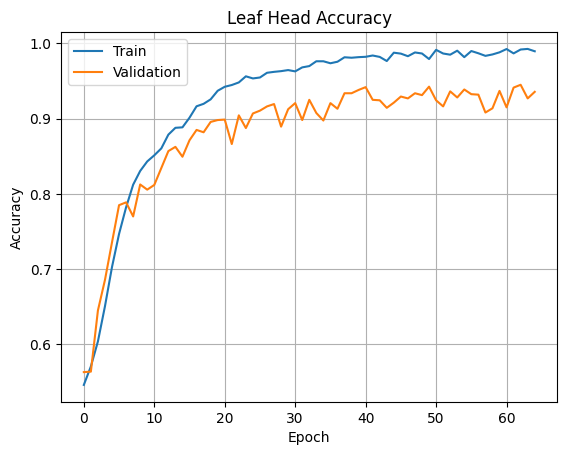

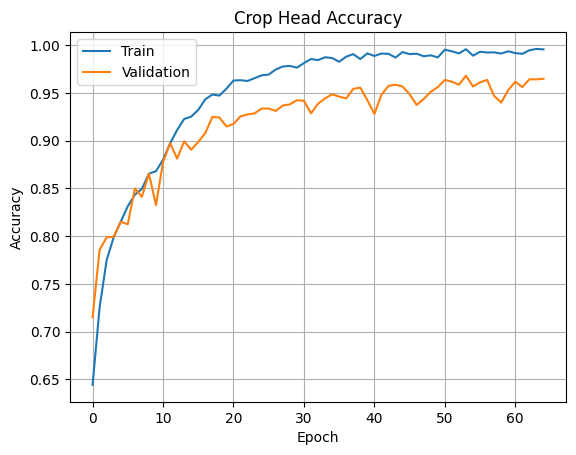

In [ ]:
import matplotlib.pyplot as plt

h = fold_histories[-1]

plt.figure()
plt.plot(h["leaf_output_accuracy"])
plt.plot(h["val_leaf_output_accuracy"])
plt.title("Leaf Head Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.grid()
plt.show()

plt.figure()
plt.plot(h["crop_output_accuracy"])
plt.plot(h["val_crop_output_accuracy"])
plt.title("Crop Head Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.grid()
plt.show()

## Step 7: Evaluation — separate metrics for leaf and crop heads

`model.predict()` now returns a list `[leaf_preds, crop_preds]` instead of one array,
so accuracy/precision/recall/F1 and confusion matrices are computed twice.

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import numpy as np

val_df = df.iloc[val_idx]
val_ds_eval = make_dataset(val_df, training=False)

y_true_leaf = val_df["leaf_label"].map(leaf_to_idx).values
y_true_crop = val_df["crop_label"].map(crop_to_idx).values

leaf_preds, crop_preds = model.predict(val_ds_eval)
y_pred_leaf = np.argmax(leaf_preds, axis=1)
y_pred_crop = np.argmax(crop_preds, axis=1)

print("=== Leaf head ===")
print(f"Accuracy:  {accuracy_score(y_true_leaf, y_pred_leaf):.4f}")
print(f"Precision: {precision_score(y_true_leaf, y_pred_leaf, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_true_leaf, y_pred_leaf, average='weighted'):.4f}")
print(f"F1-score:  {f1_score(y_true_leaf, y_pred_leaf, average='weighted'):.4f}")
print(classification_report(y_true_leaf, y_pred_leaf, target_names=leaf_classes))

print("=== Crop head ===")
print(f"Accuracy:  {accuracy_score(y_true_crop, y_pred_crop):.4f}")
print(f"Precision: {precision_score(y_true_crop, y_pred_crop, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_true_crop, y_pred_crop, average='weighted'):.4f}")
print(f"F1-score:  {f1_score(y_true_crop, y_pred_crop, average='weighted'):.4f}")
print(classification_report(y_true_crop, y_pred_crop, target_names=crop_classes))

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step
=== Leaf head ===
Accuracy:  0.9356
Precision: 0.9375
Recall:    0.9356
F1-score:  0.9355
              precision    recall  f1-score   support

     healthy       0.91      0.97      0.94       808
   unhealthy       0.97      0.90      0.93       792

    accuracy                           0.94      1600
   macro avg       0.94      0.94      0.94      1600
weighted avg       0.94      0.94      0.94      1600

=== Crop head ===
Accuracy:  0.9650
Precision: 0.9655
Recall:    0.9650
F1-score:  0.9650
              precision    recall  f1-score   support

     healthy       0.98      0.95      0.96       776
      rotten       0.95      0.98      0.97       824

    accuracy                           0.96      1600
   macro avg       0.97      0.96      0.96      1600
weighted avg       0.97      0.96      0.96      1600



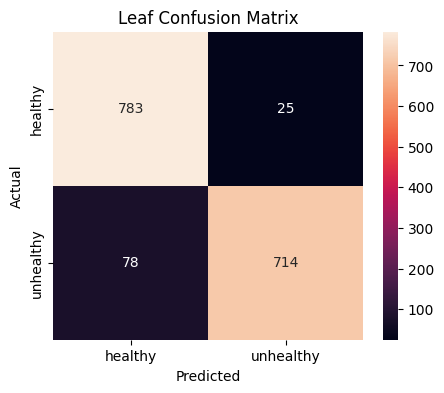

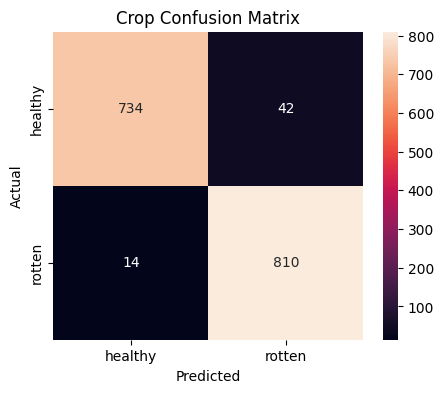

In [ ]:
import seaborn as sns

for name, y_t, y_p, class_names in [
    ("Leaf", y_true_leaf, y_pred_leaf, leaf_classes),
    ("Crop", y_true_crop, y_pred_crop, crop_classes),
]:
    cm = confusion_matrix(y_t, y_p)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

## Step 7.5: (Optional) Content-Type Detector as a cross-check

Because the multitask model is now trained with a `none` class, **it already decides on
its own** whether a photo is leaf-only, crop-only, or both:
- leaf head != none and crop head == none  -> leaf only
- leaf head == none and crop head != none  -> crop only
- both heads != none                       -> both

This small 3-class MobileNetV2 detector is kept as an **independent second opinion**.
The inference cell (Step 8) uses the multitask model's `none` outputs as the primary
signal and can fall back to this detector only when the model is unsure.


In [ ]:
import random
import pandas as pd

rng_det = random.Random(42)

# All available single-object photos, and the true composite rows from df
leaf_all = [p for k in sorted(leaf_files) for p in leaf_files[k]]
crop_all = [p for k in sorted(crop_files) for p in crop_files[k]]
composite_rows = df[(df["leaf_label"] != "none") & (df["crop_label"] != "none")]
both_all = list(composite_rows["filepath"].unique())

# Balance all three type classes to the same size
n_each = min(len(leaf_all), len(crop_all), len(both_all))
print(f"Balancing detector to {n_each} images per type class")

detector_records = []
for p in rng_det.sample(leaf_all, n_each):
    detector_records.append((p, "leaf_only"))
for p in rng_det.sample(crop_all, n_each):
    detector_records.append((p, "crop_only"))
for p in rng_det.sample(both_all, n_each):
    detector_records.append((p, "both"))

detector_df = pd.DataFrame(detector_records, columns=["filepath", "type_label"])
detector_df = detector_df.sample(frac=1, random_state=42).reset_index(drop=True)

print(detector_df["type_label"].value_counts().sort_index())
assert detector_df["type_label"].value_counts().nunique() == 1, "detector not balanced!"
print("[OK] detector type classes are balanced.")


In [ ]:
from sklearn.model_selection import train_test_split

type_classes = sorted(detector_df["type_label"].unique())
type_to_idx = {c: i for i, c in enumerate(type_classes)}
print("Type classes:", type_classes)

train_det_df, val_det_df = train_test_split(
    detector_df, test_size=0.15, stratify=detector_df["type_label"], random_state=42
)

def load_and_preprocess_type(filepath, type_idx):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    type_onehot = tf.one_hot(type_idx, depth=len(type_classes))
    return img, type_onehot

def make_type_dataset(sub_df, training=True):
    filepaths = sub_df["filepath"].values
    type_idx = sub_df["type_label"].map(type_to_idx).values
    ds = tf.data.Dataset.from_tensor_slices((filepaths, type_idx))
    ds = ds.map(load_and_preprocess_type, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(1024, seed=42)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_type_ds = make_type_dataset(train_det_df, training=True)
val_type_ds = make_type_dataset(val_det_df, training=False)


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model

def build_type_detector(img_size=256, num_classes=3):
    inputs = layers.Input(shape=(img_size, img_size, 3))
    base = MobileNetV2(include_top=False, weights="imagenet", input_tensor=inputs)
    base.trainable = False  # frozen backbone -- this is a lightweight helper model

    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="type_output")(x)
    return Model(inputs, outputs, name="content_type_detector")

type_detector = build_type_detector(num_classes=len(type_classes))
type_detector.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
type_detector.summary()

detector_history = type_detector.fit(
    train_type_ds, validation_data=val_type_ds, epochs=10
)
type_detector.save("/content/content_type_detector.h5")


## Step 8: Inference on a new image (type-aware, model-driven)

Give any photo (upload in Colab, or set `img_path` to a local file). The multitask
model predicts both heads; whichever head returns `none` is suppressed, so:
- **leaf-only photo**  -> only `Leaf: healthy/unhealthy` is shown
- **crop-only photo**  -> only `Crop: healthy/rotten` is shown
- **photo with both**  -> both lines are shown

The separate content-type detector (if trained) is printed as a cross-check.


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Get an image path. In Colab this opens an upload dialog; otherwise set img_path
# manually, e.g.  img_path = "/content/my_leaf.jpg"
# ---------------------------------------------------------------------------
try:
    from google.colab import files
    uploaded = files.upload()
    img_path = list(uploaded.keys())[0]
except Exception:
    # not in Colab (or user cancelled) -> set your own path here
    img_path = globals().get("img_path", None)
    assert img_path, "Set img_path to a local image file."

print("Image:", img_path)

img = tf.keras.utils.load_img(img_path, target_size=(256, 256))
img_array = tf.keras.utils.img_to_array(img)
img_input = np.expand_dims(img_array / 255.0, axis=0)

# ---------------------------------------------------------------------------
# 1) Multitask model -- PRIMARY signal. Each head may output "none".
# ---------------------------------------------------------------------------
leaf_pred, crop_pred = model.predict(img_input, verbose=0)

leaf_idx = int(np.argmax(leaf_pred[0]))
crop_idx = int(np.argmax(crop_pred[0]))
leaf_result = leaf_classes[leaf_idx]
crop_result = crop_classes[crop_idx]
leaf_conf = float(leaf_pred[0][leaf_idx]) * 100
crop_conf = float(crop_pred[0][crop_idx]) * 100

leaf_present = (leaf_result != "none")
crop_present = (crop_result != "none")

# ---------------------------------------------------------------------------
# 2) Derive the content type from the model itself
# ---------------------------------------------------------------------------
if leaf_present and crop_present:
    detected_type = "both"
elif leaf_present:
    detected_type = "leaf_only"
elif crop_present:
    detected_type = "crop_only"
else:
    detected_type = "unknown"   # both heads said none -> unclear image

# ---------------------------------------------------------------------------
# 3) Optional cross-check with the standalone content-type detector
# ---------------------------------------------------------------------------
detector_note = ""
if "type_detector" in globals():
    type_probs = type_detector.predict(img_input, verbose=0)[0]
    det_type = type_classes[int(np.argmax(type_probs))]
    det_conf = float(np.max(type_probs)) * 100
    detector_note = f"(detector cross-check: {det_type}, {det_conf:.1f}%)"
    # if the model was unsure, defer to the detector
    if detected_type == "unknown":
        detected_type = det_type

# ---------------------------------------------------------------------------
# 4) Report only the head(s) that apply
# ---------------------------------------------------------------------------
lines = []
if detected_type in ("leaf_only", "both") and leaf_present:
    lines.append(f"Leaf: {leaf_result} ({leaf_conf:.1f}%)")
if detected_type in ("crop_only", "both") and crop_present:
    lines.append(f"Crop: {crop_result} ({crop_conf:.1f}%)")
if not lines:
    lines.append("Could not confidently identify a leaf or crop in this image.")

plt.figure(figsize=(5, 5))
plt.imshow(img_array.astype("uint8"))
plt.title(f"Detected: {detected_type}\n" + "\n".join(lines))
plt.axis("off")
plt.show()

print(f"\nDetected content type: {detected_type}  {detector_note}")
for l in lines:
    print("  " + l)


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

def plot_roc_multiclass(y_true, probs, class_names, title):
    """One-vs-rest ROC for each class, plus macro-average AUC.
    Works whether a head has 2 or 3 classes (e.g. healthy/none/unhealthy)."""
    n_classes = len(class_names)
    y_bin = label_binarize(y_true, classes=list(range(n_classes)))
    if n_classes == 2:                       # label_binarize gives 1 col for binary
        y_bin = np.hstack([1 - y_bin, y_bin])

    plt.figure(figsize=(6, 5))
    aucs = []
    for i, cname in enumerate(class_names):
        if y_bin[:, i].sum() == 0:           # class absent in this val split
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
        auc_i = roc_auc_score(y_bin[:, i], probs[:, i])
        aucs.append(auc_i)
        plt.plot(fpr, tpr, label=f"{cname} (AUC={auc_i:.3f})")

    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend()
    plt.show()
    macro = float(np.mean(aucs)) if aucs else float("nan")
    return macro

leaf_auc = plot_roc_multiclass(y_true_leaf, leaf_preds, leaf_classes, "Leaf ROC (one-vs-rest)")
crop_auc = plot_roc_multiclass(y_true_crop, crop_preds, crop_classes, "Crop ROC (one-vs-rest)")
print(f"Leaf macro-AUC: {leaf_auc:.4f},  Crop macro-AUC: {crop_auc:.4f}")


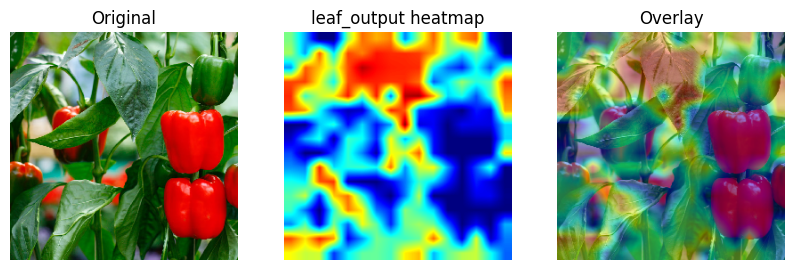

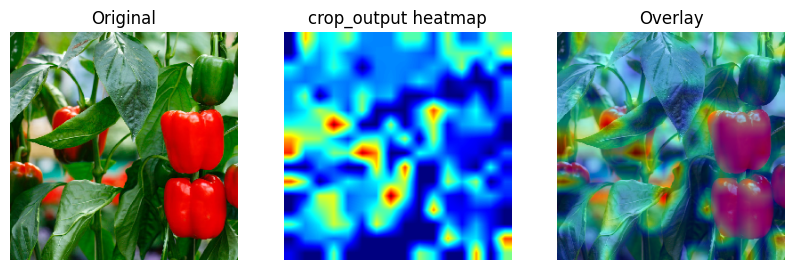

In [ ]:
import tensorflow as tf
import numpy as np
import cv2

def make_gradcam_heatmap(img_array, model, output_name, class_index=None, patch_grid=16):
    pool_layer = next(l for l in model.layers if isinstance(l, tf.keras.layers.GlobalAveragePooling1D))
    feature_layer_output = pool_layer.input   # (B, num_patches, embed_dim)

    grad_model = tf.keras.models.Model(
        inputs=model.input,
        outputs=[feature_layer_output, model.get_layer(output_name).output]
    )

    with tf.GradientTape() as tape:
        patch_features, preds = grad_model(img_array)
        if class_index is None:
            class_index = tf.argmax(preds[0])
        class_channel = preds[:, class_index]

    grads = tape.gradient(class_channel, patch_features)         # (B, num_patches, embed_dim)
    pooled_grads = tf.reduce_mean(grads, axis=1)                 # channel importance

    weighted = patch_features * pooled_grads[:, tf.newaxis, :]
    heatmap = tf.reduce_sum(weighted, axis=-1)                   # (B, num_patches)
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return tf.reshape(heatmap, (patch_grid, patch_grid)).numpy()


def show_gradcam(img_path, model, output_name, img_size=256, patch_size=16):
    img = tf.keras.utils.load_img(img_path, target_size=(img_size, img_size))
    img_array = tf.keras.utils.img_to_array(img) / 255.0
    img_input = np.expand_dims(img_array, axis=0)

    heatmap = make_gradcam_heatmap(img_input, model, output_name, patch_grid=img_size // patch_size)
    heatmap_resized = cv2.resize(heatmap, (img_size, img_size))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    overlay = (np.uint8(img_array * 255) * 0.6 + heatmap_color * 0.4).astype("uint8")

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 3, 1); plt.imshow(img_array); plt.title("Original"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(heatmap_color); plt.title(f"{output_name} heatmap"); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(overlay); plt.title("Overlay"); plt.axis("off")
    plt.show()

# Compare where each head is actually looking, on the SAME image
show_gradcam(img_path, model, "leaf_output")
show_gradcam(img_path, model, "crop_output")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 14.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=ed272b69a802a1aee775beb1a379cfc6d95b080672cd7437068fa60a85f65347
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


  0%|          | 0/1000 [00:00<?, ?it/s]

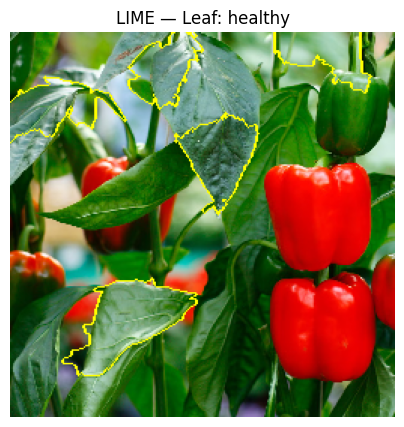

  0%|          | 0/1000 [00:00<?, ?it/s]

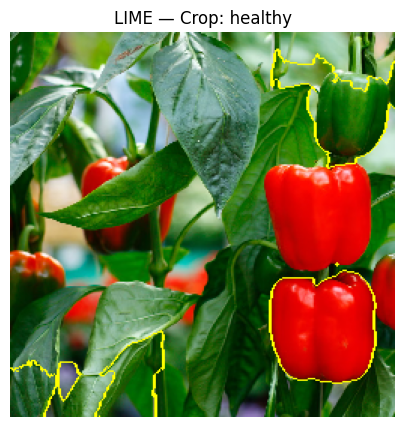

In [ ]:
import matplotlib.pyplot as plt
!pip install lime
from lime import lime_image
from skimage.segmentation import mark_boundaries

def predict_fn_leaf(images):
    images = images.astype("float32") / 255.0
    leaf_preds, _ = model.predict(images, verbose=0)
    return leaf_preds

def predict_fn_crop(images):
    images = images.astype("float32") / 255.0
    _, crop_preds = model.predict(images, verbose=0)
    return crop_preds

def show_lime(img_path, predict_fn, class_names, title):
    img = tf.keras.utils.load_img(img_path, target_size=(256, 256))
    img_array = tf.keras.utils.img_to_array(img).astype("uint8")

    explainer = lime_image.LimeImageExplainer()
    explanation = explainer.explain_instance(
        img_array, predict_fn, top_labels=2, hide_color=0, num_samples=1000
    )
    top_label = explanation.top_labels[0]
    temp, mask = explanation.get_image_and_mask(
        top_label, positive_only=True, num_features=5, hide_rest=False
    )

    plt.figure(figsize=(5, 5))
    plt.imshow(mark_boundaries(temp / 255.0, mask))
    plt.title(f"{title}: {class_names[top_label]}")
    plt.axis("off")
    plt.show()

show_lime(img_path, predict_fn_leaf, leaf_classes, "LIME — Leaf")
show_lime(img_path, predict_fn_crop, crop_classes, "LIME — Crop")

In [ ]:
import numpy as np

leaf_accs = [h['val_leaf_output_accuracy'][-1] for h in fold_histories]
crop_accs = [h['val_crop_output_accuracy'][-1] for h in fold_histories]

print(f"Leaf accuracy: {np.mean(leaf_accs):.4f} ± {np.std(leaf_accs):.4f}")
print(f"Crop accuracy: {np.mean(crop_accs):.4f} ± {np.std(crop_accs):.4f}")

# 95% confidence interval
from scipy import stats
ci = stats.t.interval(0.95, len(leaf_accs)-1, loc=np.mean(leaf_accs), scale=stats.sem(leaf_accs))
print(f"95% CI for leaf accuracy: {ci}")

Leaf accuracy: 0.9419 ± 0.0000
Crop accuracy: 0.9463 ± 0.0000
95% CI for leaf accuracy: (np.float64(nan), np.float64(nan))


/tmp/ipykernel_873/3754677553.py:11: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ci = stats.t.interval(0.95, len(leaf_accs)-1, loc=np.mean(leaf_accs), scale=stats.sem(leaf_accs))


In [ ]:
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay, average_precision_score
import matplotlib.pyplot as plt

# Heads are now 3-class (healthy / none / unhealthy|rotten). We plot the PR curve for
# the clinically relevant "disease" class using its column index in the softmax output.
leaf_pos_idx = leaf_to_idx["unhealthy"]
crop_pos_idx = crop_to_idx["rotten"]

# Binary ground truth: 1 = the disease class, 0 = anything else (healthy or none)
y_true_leaf_binary = (y_true_leaf == leaf_pos_idx).astype(int)
y_true_crop_binary = (y_true_crop == crop_pos_idx).astype(int)

# --- Leaf head ---
precision_leaf, recall_leaf, _ = precision_recall_curve(y_true_leaf_binary, leaf_preds[:, leaf_pos_idx])
pr_auc_leaf = average_precision_score(y_true_leaf_binary, leaf_preds[:, leaf_pos_idx])
PrecisionRecallDisplay(precision=precision_leaf, recall=recall_leaf,
                       average_precision=pr_auc_leaf).plot()
plt.title(f"Leaf PR Curve — 'unhealthy' (AP={pr_auc_leaf:.3f})")
plt.grid(True); plt.show()
print(f"Leaf 'unhealthy' Average Precision (AP): {pr_auc_leaf:.4f}")

# --- Crop head ---
precision_crop, recall_crop, _ = precision_recall_curve(y_true_crop_binary, crop_preds[:, crop_pos_idx])
pr_auc_crop = average_precision_score(y_true_crop_binary, crop_preds[:, crop_pos_idx])
PrecisionRecallDisplay(precision=precision_crop, recall=recall_crop,
                       average_precision=pr_auc_crop).plot()
plt.title(f"Crop PR Curve — 'rotten' (AP={pr_auc_crop:.3f})")
plt.grid(True); plt.show()
print(f"Crop 'rotten' Average Precision (AP): {pr_auc_crop:.4f}")


## Summary of Model Evaluation Metrics

In [ ]:
print("### Leaf Head Metrics:")
print(f"- Average Accuracy: {np.mean(leaf_accs):.4f} ")
# Confidence interval was NaN due to small sample size
print(f"- Accuracy: {accuracy_score(y_true_leaf, y_pred_leaf):.4f}")
print(f"- Precision (weighted): {precision_score(y_true_leaf, y_pred_leaf, average='weighted'):.4f}")
print(f"- Recall (weighted): {recall_score(y_true_leaf, y_pred_leaf, average='weighted'):.4f}")
print(f"- F1-score (weighted): {f1_score(y_true_leaf, y_pred_leaf, average='weighted'):.4f}")
print(f"- ROC AUC: {leaf_auc:.4f}")
print(f"- Average Precision (AP): {pr_auc_leaf:.4f}")

print("\n### Crop Head Metrics:")
print(f"- Average Accuracy: {np.mean(crop_accs):.4f}")
print(f"- Accuracy: {accuracy_score(y_true_crop, y_pred_crop):.4f}")
print(f"- Precision (weighted): {precision_score(y_true_crop, y_pred_crop, average='weighted'):.4f}")
print(f"- Recall (weighted): {recall_score(y_true_crop, y_pred_crop, average='weighted'):.4f}")
print(f"- F1-score (weighted): {f1_score(y_true_crop, y_pred_crop, average='weighted'):.4f}")
print(f"- ROC AUC: {crop_auc:.4f}")
print(f"- Average Precision (AP): {pr_auc_crop:.4f}")


### Leaf Head Metrics:
- Average Accuracy: 0.9419 
- Accuracy: 0.8806
- Precision (weighted): 0.8892
- Recall (weighted): 0.8806
- F1-score (weighted): 0.8803
- ROC AUC: 0.9591
- Average Precision (AP): 0.9649

### Crop Head Metrics:
- Average Accuracy: 0.9463
- Accuracy: 0.9200
- Precision (weighted): 0.9213
- Recall (weighted): 0.9200
- F1-score (weighted): 0.9200
- ROC AUC: 0.9785
- Average Precision (AP): 0.9774


## Loss vs. Epoch Plots

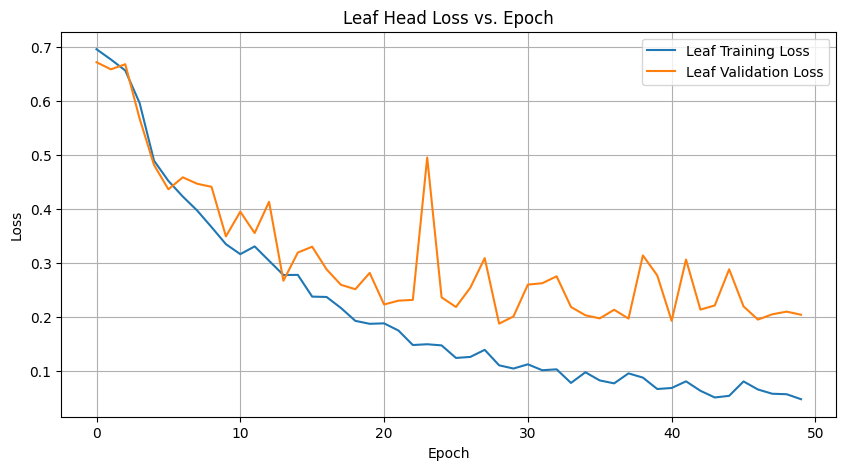

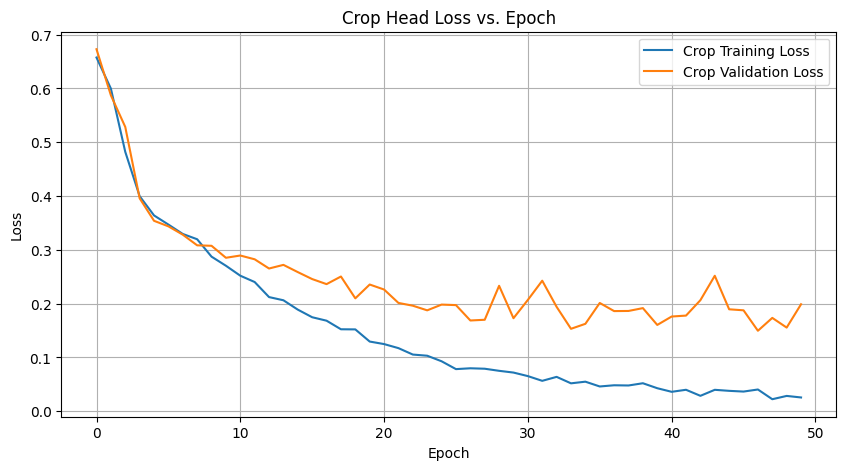

In [ ]:
import matplotlib.pyplot as plt

h = fold_histories[-1] # Assuming the last fold's history

plt.figure(figsize=(10, 5))
plt.plot(h["leaf_output_loss"], label='Leaf Training Loss')
plt.plot(h["val_leaf_output_loss"], label='Leaf Validation Loss')
plt.title("Leaf Head Loss vs. Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(h["crop_output_loss"], label='Crop Training Loss')
plt.plot(h["val_crop_output_loss"], label='Crop Validation Loss')
plt.title("Crop Head Loss vs. Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

## Analyze Misclassified Images

Number of misclassified leaf samples: 191
Number of misclassified crop samples: 128

--- Top 5 Misclassified Leaf Images ---


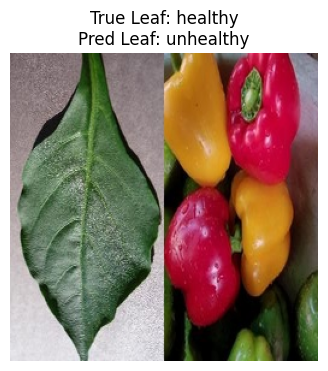

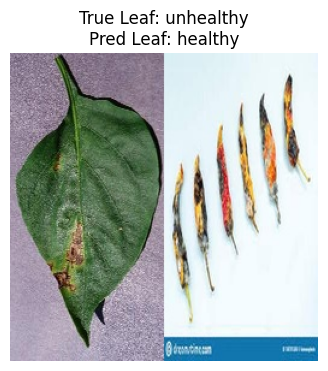

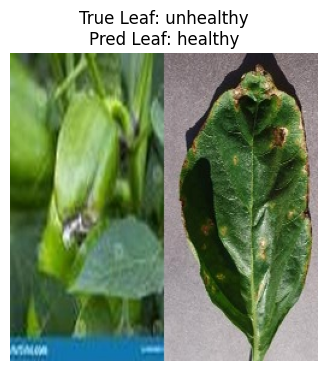

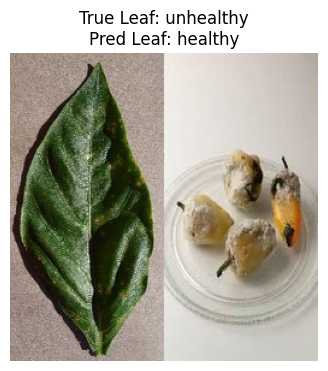

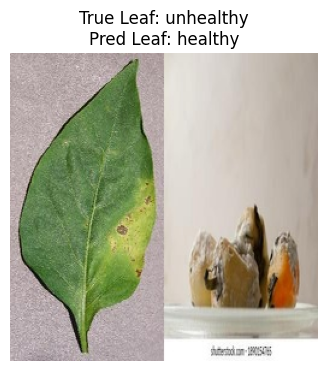


--- Top 5 Misclassified Crop Images ---


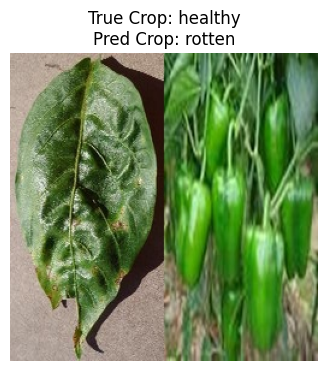

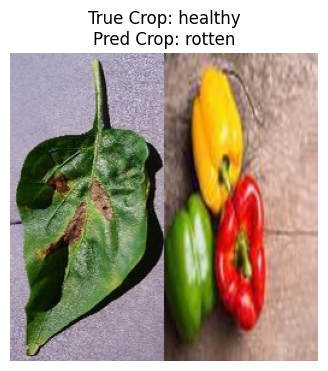

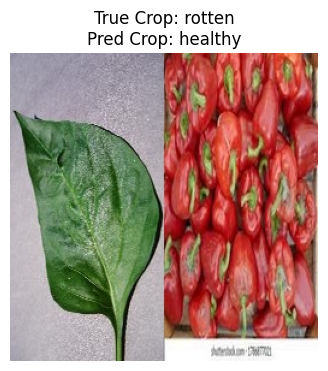

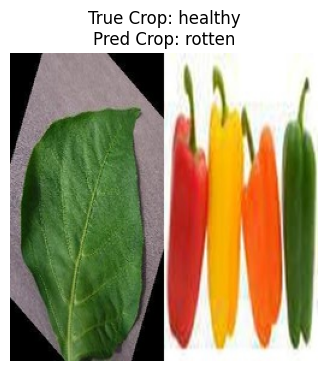

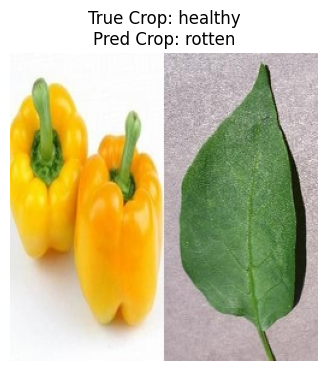

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Identify misclassified samples for leaf head
misclassified_leaf_indices = np.where(y_true_leaf != y_pred_leaf)[0]

# Identify misclassified samples for crop head
misclassified_crop_indices = np.where(y_true_crop != y_pred_crop)[0]

print(f"Number of misclassified leaf samples: {len(misclassified_leaf_indices)}")
print(f"Number of misclassified crop samples: {len(misclassified_crop_indices)}")

def display_misclassified_images(indices, head_name, true_labels, pred_labels, class_names, df_subset, num_to_display=5):
    print(f"\n--- Top {num_to_display} Misclassified {head_name} Images ---")
    displayed_count = 0
    for i in indices:
        if displayed_count >= num_to_display:
            break

        filepath = df_subset.iloc[i]['filepath']
        true_label_idx = true_labels[i]
        predicted_label_idx = pred_labels[i]

        img = tf.keras.utils.load_img(filepath, target_size=(256, 256))
        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.title(f"True {head_name}: {class_names[true_label_idx]}\nPred {head_name}: {class_names[predicted_label_idx]}")
        plt.axis('off')
        plt.show()
        displayed_count += 1

# Display some misclassified leaf images
display_misclassified_images(misclassified_leaf_indices, 'Leaf', y_true_leaf, y_pred_leaf, leaf_classes, val_df, num_to_display=5)

# Display some misclassified crop images
display_misclassified_images(misclassified_crop_indices, 'Crop', y_true_crop, y_pred_crop, crop_classes, val_df, num_to_display=5)

## Error Analysis Summary by True Label

In [ ]:
from sklearn.metrics import confusion_matrix

def analyze_misclassifications_by_true_label(y_true, y_pred, class_names, head_name):
    print(f"\n--- Misclassification Analysis for {head_name} Head (Grouped by True Label) ---")
    cm = confusion_matrix(y_true, y_pred)

    for i, true_class_name in enumerate(class_names):
        total_true_class_samples = np.sum(cm[i, :])
        correctly_classified = cm[i, i]
        misclassified_count = total_true_class_samples - correctly_classified

        if misclassified_count > 0:
            print(f"True {head_name} Class: '{true_class_name}' ({total_true_class_samples} samples total)")
            print(f"  - Correctly Classified: {correctly_classified} samples ({correctly_classified/total_true_class_samples:.2%})")
            print(f"  - Misclassified: {misclassified_count} samples ({misclassified_count/total_true_class_samples:.2%})")
            for j, predicted_class_name in enumerate(class_names):
                if i != j and cm[i, j] > 0:
                    print(f"    -> Predicted as '{predicted_class_name}': {cm[i, j]} samples")
            print()
        else:
            print(f"True {head_name} Class: '{true_class_name}' (All {total_true_class_samples} samples correctly classified)")
            print()

# Analyze Leaf Head
analyze_misclassifications_by_true_label(y_true_leaf, y_pred_leaf, leaf_classes, 'Leaf')

# Analyze Crop Head
analyze_misclassifications_by_true_label(y_true_crop, y_pred_crop, crop_classes, 'Crop')


--- Misclassification Analysis for Leaf Head (Grouped by True Label) ---
True Leaf Class: 'healthy' (770 samples total)
  - Correctly Classified: 732 samples (95.06%)
  - Misclassified: 38 samples (4.94%)
    -> Predicted as 'unhealthy': 38 samples

True Leaf Class: 'unhealthy' (830 samples total)
  - Correctly Classified: 677 samples (81.57%)
  - Misclassified: 153 samples (18.43%)
    -> Predicted as 'healthy': 153 samples


--- Misclassification Analysis for Crop Head (Grouped by True Label) ---
True Crop Class: 'healthy' (811 samples total)
  - Correctly Classified: 725 samples (89.40%)
  - Misclassified: 86 samples (10.60%)
    -> Predicted as 'rotten': 86 samples

True Crop Class: 'rotten' (789 samples total)
  - Correctly Classified: 747 samples (94.68%)
  - Misclassified: 42 samples (5.32%)
    -> Predicted as 'healthy': 42 samples



## Analyze Doubly Misclassified Images (Leaf and Crop Heads Both Incorrect)

Number of doubly misclassified samples (both leaf and crop incorrect): 11

--- Top 5 Doubly Misclassified Images ---


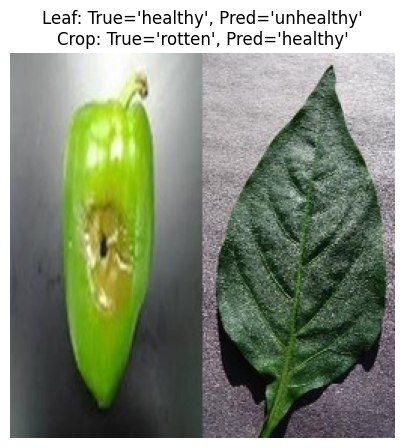

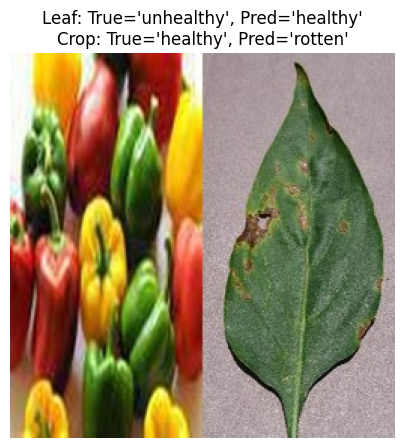

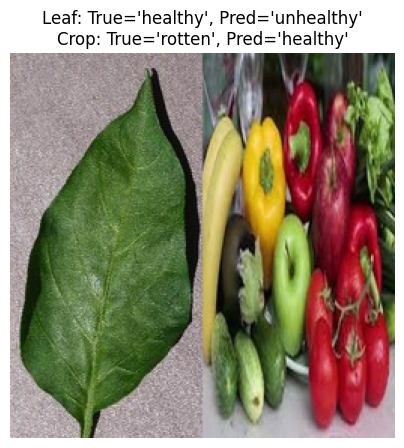

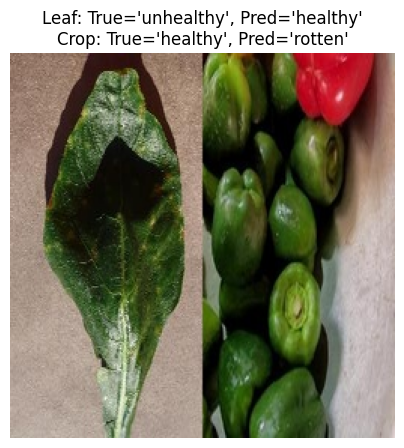

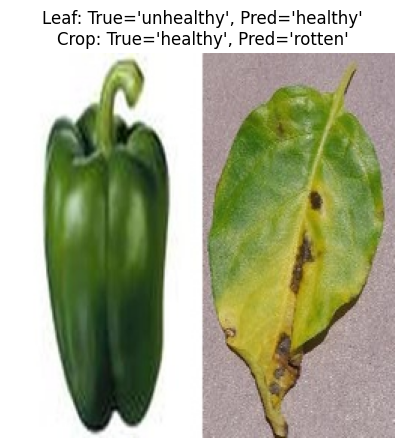

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Identify indices where leaf prediction was incorrect
misclassified_leaf_mask = (y_true_leaf != y_pred_leaf)

# Identify indices where crop prediction was incorrect
misclassified_crop_mask = (y_true_crop != y_pred_crop)

# Find indices where BOTH leaf and crop predictions were incorrect
doubly_misclassified_indices = np.where(misclassified_leaf_mask & misclassified_crop_mask)[0]

print(f"Number of doubly misclassified samples (both leaf and crop incorrect): {len(doubly_misclassified_indices)}")

def display_doubly_misclassified_images(indices, df_subset, leaf_true, leaf_pred, leaf_names, crop_true, crop_pred, crop_names, num_to_display=5):
    print(f"\n--- Top {min(num_to_display, len(indices))} Doubly Misclassified Images ---")
    displayed_count = 0
    for i in indices:
        if displayed_count >= num_to_display:
            break

        filepath = df_subset.iloc[i]['filepath']

        true_leaf_label = leaf_names[leaf_true[i]]
        predicted_leaf_label = leaf_names[leaf_pred[i]]

        true_crop_label = crop_names[crop_true[i]]
        predicted_crop_label = crop_names[crop_pred[i]]

        img = tf.keras.utils.load_img(filepath, target_size=(256, 256))
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.title(
            f"Leaf: True='{true_leaf_label}', Pred='{predicted_leaf_label}'\n"
            f"Crop: True='{true_crop_label}', Pred='{predicted_crop_label}'"
        )
        plt.axis('off')
        plt.show()
        displayed_count += 1

# Display some of the doubly misclassified images
display_doubly_misclassified_images(
    doubly_misclassified_indices,
    val_df,
    y_true_leaf, y_pred_leaf, leaf_classes,
    y_true_crop, y_pred_crop, crop_classes,
    num_to_display=5
)

## Accuracy per Class Bar Charts

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

def plot_per_class_precision(y_true, y_pred, class_names, head_name, cmap_name):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
    col_sums = cm.sum(axis=0)
    with np.errstate(divide="ignore", invalid="ignore"):
        precision_per_class = np.where(col_sums > 0, cm.diagonal() / col_sums, 0.0)

    colors = plt.get_cmap(cmap_name)(np.linspace(0.4, 0.8, len(class_names)))
    plt.figure(figsize=(8, 5))
    plt.bar(class_names, precision_per_class, color=colors)
    plt.title(f"{head_name} Head: Precision per Class")
    plt.xlabel("Class"); plt.ylabel("Precision"); plt.ylim(0, 1)
    for i, p in enumerate(precision_per_class):
        plt.text(i, p + 0.02, f"{p:.2f}", ha="center", va="bottom")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.show()

plot_per_class_precision(y_true_leaf, y_pred_leaf, leaf_classes, "Leaf", "Blues")
plot_per_class_precision(y_true_crop, y_pred_crop, crop_classes, "Crop", "Greens")


## Confidence Analysis: Correct vs. Incorrect Predictions

In [ ]:
import numpy as np

def analyze_confidence(y_true, y_pred, raw_preds, head_name):
    # Get the confidence for the predicted class for each sample
    predicted_confidences = raw_preds[np.arange(len(y_pred)), y_pred]

    # Masks for correct and incorrect predictions
    correct_mask = (y_true == y_pred)
    incorrect_mask = (y_true != y_pred)

    # Calculate mean confidence for correct predictions
    if np.any(correct_mask):
        mean_correct_confidence = np.mean(predicted_confidences[correct_mask])
    else:
        mean_correct_confidence = 0 # No correct predictions

    # Calculate mean confidence for incorrect predictions
    if np.any(incorrect_mask):
        mean_incorrect_confidence = np.mean(predicted_confidences[incorrect_mask])
    else:
        mean_incorrect_confidence = 0 # No incorrect predictions

    print(f"--- {head_name} Head Confidence Analysis ---")
    print(f"Mean confidence for CORRECT predictions: {mean_correct_confidence:.4f}")
    print(f"Mean confidence for INCORRECT predictions: {mean_incorrect_confidence:.4f}")
    print()

# Analyze Leaf Head
analyze_confidence(y_true_leaf, y_pred_leaf, leaf_preds, 'Leaf')

# Analyze Crop Head
analyze_confidence(y_true_crop, y_pred_crop, crop_preds, 'Crop')

--- Leaf Head Confidence Analysis ---
Mean confidence for CORRECT predictions: 0.9364
Mean confidence for INCORRECT predictions: 0.7772

--- Crop Head Confidence Analysis ---
Mean confidence for CORRECT predictions: 0.9499
Mean confidence for INCORRECT predictions: 0.7497

